# Adversarial objectives and controlled restoration

Compare hinge/SN, non-saturating/R1, least-squares and Wasserstein-GP with direct fine-tuning on colorization and 4× SR. All five share the same generator warm start within each seed. Selection includes epoch 0; unsuccessful changes remain visible. The experiment measures conditional deterministic restoration, not unconditional generation.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd() if Path("configs").exists() else Path.cwd().parent
sys.path.insert(0, str(root / "src"))

import torch
from torch import nn
from learning_lab.adversarial import gradient_penalty, r1_penalty, critic_objective, generator_objective


## Critic and generator signs

The Wasserstein critic minimizes mean fake minus mean real. The generator minimizes negative mean fake. R1 differentiates real examples; WGAN-GP interpolates real/fake RGB while keeping the observed condition fixed.

In [2]:
real = torch.tensor([2.0, 3.0], requires_grad=True)
fake = torch.tensor([-1.0, 0.0], requires_grad=True)
pd.DataFrame([{ "method": method, "critic": float(critic_objective(real, fake, method).detach()), "generator": float(generator_objective(fake, method).detach()) }
    for method in ["hinge_sn", "non_saturating_r1", "least_squares", "wasserstein_gp"]])

,method,critic,generator
0,hinge_sn,0.250000,0.500000
1,non_saturating_r1,0.590962,1.003204
2,least_squares,1.500000,1.250000
3,wasserstein_gp,-3.000000,0.500000


## An analytic gradient-penalty check

A scalar linear critic with a unit RGB gradient has zero interpolant penalty. The condition contributes to its score but does not enter the RGB norm. Second derivatives must remain in the graph for trainable critics.

In [3]:
class LinearCritic(nn.Module):
    def forward(self, condition, rgb):
        return rgb.flatten(1).sum(1) / (rgb[0].numel() ** 0.5) + condition.flatten(1).sum(1)
rgb = torch.randn(3, 3, 4, 4)
condition = torch.randn(3, 1, 4, 4)
gp, norm = gradient_penalty(LinearCritic(), condition, rgb, torch.zeros_like(rgb))
assert float(gp) < 1e-12
print("Gradient norm:", float(norm), "Penalty:", float(gp))

Gradient norm: 0.9999997615814209 Penalty: 5.684341886080802e-14


## All epochs and selected checkpoints

Validation uses field L1 plus a frozen-feature loss. It is not a perceptual-realism oracle. If later adversarial updates worsen that criterion, the initial model remains selected after the full budget completes.

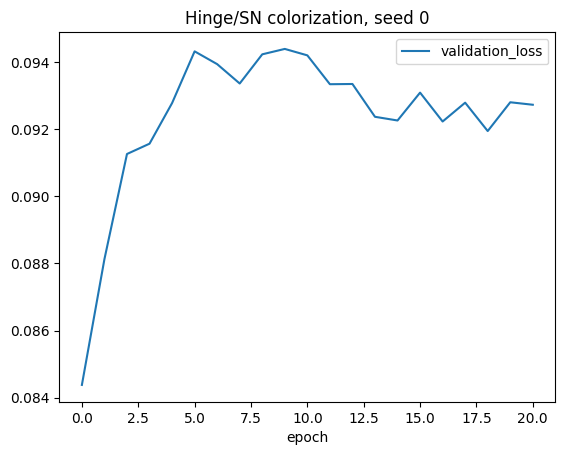

In [4]:
history = json.loads((root / "results/reference/adversarial_variants/colorization/hinge_sn/0/metrics.json").read_text())
assert history["best_epoch"] == int(np.argmin([row["validation_loss"] for row in history["history"]]))
pd.DataFrame(history["history"])[["epoch", "validation_loss"]].plot(x="epoch", y="validation_loss", title="Hinge/SN colorization, seed 0")
plt.show()

## Fidelity, perception and uncertainty

Seed SD describes fit variability. Image intervals resample the same paired photos after averaging two seeds; they condition on those fits. These are different sources of uncertainty.

In [5]:
fits = pd.read_csv(root / "docs/adversarial_individual_fits.csv")
assert len(fits) == 20
fits.groupby(["task", "method"])[["psnr", "ssim", "lpips", "selected_epoch"]].mean().round(4)

psnr    ssim   lpips  selected_epoch
task             method                                                    
colorization     direct_finetune    24.0631  0.9283  0.1575             7.0
                 hinge_sn           24.0980  0.9281  0.1573             0.0
                 least_squares      24.0980  0.9281  0.1573             0.0
                 non_saturating_r1  24.0980  0.9281  0.1573             0.0
                 wasserstein_gp     24.0980  0.9281  0.1573             0.0
super_resolution direct_finetune    26.4260  0.7644  0.1928            20.0
                 hinge_sn           26.4109  0.7637  0.1936             0.0
                 least_squares      26.4109  0.7637  0.1936             0.0
                 non_saturating_r1  26.4109  0.7637  0.1936             0.0
                 wasserstein_gp     26.4109  0.7637  0.1936             0.0

Read [objectives and results](../docs/adversarial_results.md). Use `scripts/run_adversarial_suite.py` after preparing the original direct checkpoints. Restore your own observation with `scripts/restore_generative.py`. The [browser gallery](../docs/explorer.html) retains all four fixed photos, all methods, seeds and original stochastic draws.